## 如何切换到 HR_comma_sep.csv
1. 将 `iris_csv` 路径替换为 HR 数据集路径，例如 `Path("HR_comma_sep.csv")`。
2. 更新 `numeric_features`、`categorical_features` 为 HR 数据集中真实字段。
3. 若目标列名称不同（例如 `left`），请修改 `target_col`。
4. 数据预处理逻辑（缺失值、编码、标准化）可沿用，仅需按业务语义调整分箱或自定义特征。

In [31]:
# 步骤0：下载或复用 Iris 数据 CSV
# - 在真实作业中只需把 iris_csv 替换成 HR_comma_sep.csv
from pathlib import Path
import pandas as pd
from sklearn.datasets import load_iris

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
iris_csv = data_dir / "iris.csv"


In [32]:
# 步骤1：读取 CSV 并查看基本维度
# - 通过 pd.read_csv 载入数据帧，立刻打印样本量与字段数，确认载入成功
# - head() 展示首 5 行，了解列名及值域，为后续映射与编码做准备
df = pd.read_csv(iris_csv, encoding='gbk') # 备选 encoding='utf-8'
print(f"样本量: {df.shape[0]}, 字段数: {df.shape[1]}")
df.head()

样本量: 150, 字段数: 6


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),petal_length_bin,target
0,5.1,3.5,1.4,0.2,短,0
1,4.9,3.0,1.4,0.2,短,0
2,4.7,3.2,1.3,0.2,短,0
3,4.6,3.1,1.5,0.2,短,0
4,5.0,3.6,1.4,0.2,短,0


In [33]:
# 步骤1补充：检查数据类型与缺失情况
# - info() 能显示每列 dtype 与非空计数，确认是否需要类型转换
# - isna().sum() 汇总缺失值，若有缺失则在预处理阶段制定填补策略
df.info()
missing = df.isna().sum().to_frame(name="missing_count")
missing

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   petal_length_bin   150 non-null    object 
 5   target             150 non-null    int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


,missing_count
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
petal_length_bin,0
target,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


,ratio
target,
0,0.333333
1,0.333333
2,0.333333


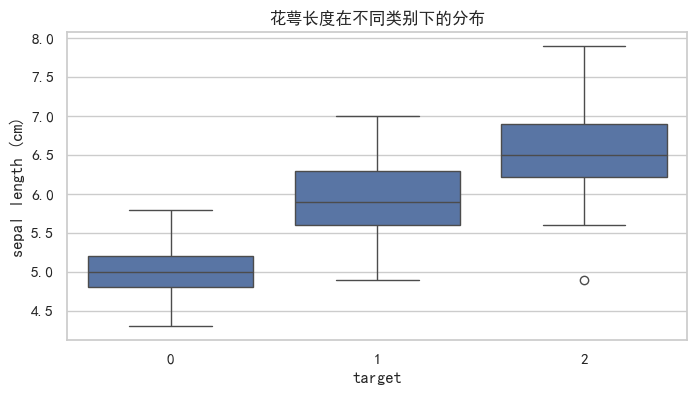

In [34]:
# 步骤2：生成描述性统计与箱线图
# - describe()、value_counts() 用于量化数值分布与类别占比，快速感知离群与不平衡
# - 箱线图对比不同类别的花萼长度，为后续特征选择提供直观证据
from IPython.display import display
import seaborn as sns
from matplotlib import font_manager
import matplotlib.pyplot as plt
# 图片Theme
sns.set_theme(style="whitegrid")

# 尝试设置常见中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False # 正常显示负号


display(df.describe())
display(df["target"].value_counts(normalize=True).to_frame(name="ratio"))

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="target", y="sepal length (cm)")
plt.title("花萼长度在不同类别下的分布")
plt.show()

### 典型 EDA 图示
- 以下代码通过直方图与成对关系图展示特征分布与特征间关系。
- 运行后可观察各品种之间在花瓣与花萼尺寸上的差异，为后续特征工程提供依据。

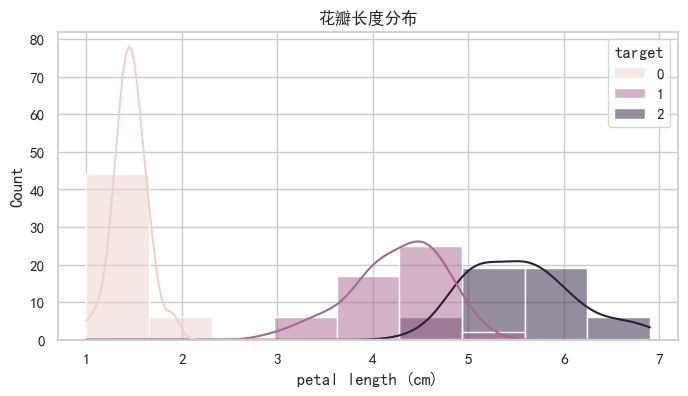

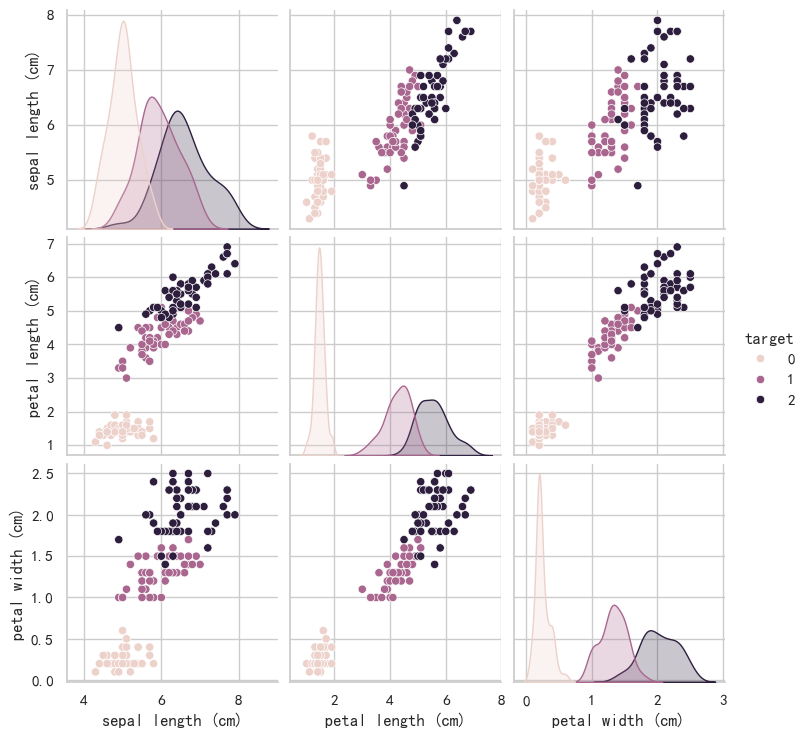

In [35]:
# 步骤2补充：绘制典型 EDA 图形
# - histplot 叠加 KDE，观察不同类别花瓣长度的重叠情况，判断分界难度
# - pairplot 显示多组特征的两两关系，可识别最能区分类别的特征组合
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="petal length (cm)", hue="target", kde=True)
plt.title("花瓣长度分布")
plt.show()

sns.pairplot(df, vars=["sepal length (cm)", "petal length (cm)", "petal width (cm)"], hue="target")
plt.show()

## 预处理与数据拆分
- 演示如何构造离散特征并统一预处理
- 划分训练/测试集，保留 20% 作为测试集

In [36]:
# 步骤3：手动完成特征预处理并划分训练/测试集
# - 说明：下面展示两种场景：
#   1) 当原始数据中没有分箱列时，可按示例用 pd.cut 构造（可选）；
#   2) 若数据中已包含真实的类别型字段，则直接将这些列加入 categorical_features 并处理。
# - 我们以 petal_length_bin 为示例类别列，同时演示数值列与类别列各自的标准处理流程

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 数值特征：根据数据字典或 dtype 判定（下例为 Iris 的数值列）
numeric_features = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

# 可选：如果你希望构造一个离散化的 petal 长度列用于演示分箱（此步可省略）
# 若真实业务数据已经有类别字段（例如 Gender、Department），直接把它们加入 categorical_features
if "petal_length_bin" not in df.columns:
    df["petal_length_bin"] = pd.cut(
        df["petal length (cm)"], bins=[0, 2, 4, 7], labels=["短", "中", "长"], include_lowest=True
    )

# 指明要作为类别处理的列（可以包含多列），示例仅包含上面生成的分箱列
categorical_features = [col for col in ["petal_length_bin"] if col in df.columns]

target_col = "target"

# 确保类别列为字符串或 category 类型，便于后续独热编码
# 注意：保留为 pandas.Categorical 可以保留顺序信息并节省内存
for c in categorical_features:
    df[c] = df[c].astype("category")

# 使用 pd.get_dummies 对所有类别列做独热编码（也可用 OneHotEncoder）
# 若不希望生成 NaN->'nan' 的字符串，请保持 dtype 为 category 或在编码前处理缺失
if categorical_features:
    df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=False)
else:
    df_encoded = df.copy()

# X / y 分离
X = df_encoded.drop(columns=[target_col]).copy()
y = df_encoded[target_col].copy()

# 使用 train_test_split 将数据分为训练集 (80%) 与测试集 (20%)，并保持类别比例一致
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 只对数值特征做标准化，类别编码列保持为 0/1
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# 注意：在 df_encoded 中，独热列名是原类别名的展开形式，因此 numeric_features 在 X_train 中仍然存在
X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

print("训练集形状:", X_train_scaled.shape)
print("测试集形状:", X_test_scaled.shape)


训练集形状: (120, 7)
测试集形状: (30, 7)


## 逻辑回归模型训练与评估

In [37]:
# 步骤4：构建带预处理的逻辑回归基线模型
# - 这里直接实例化 LogisticRegression，参数 multi_class="multinomial" 适用于多分类问题
# - max_iter 设置为 1000 以保证收敛，同时保留默认 L2 正则
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logit_clf = LogisticRegression(max_iter=1000)

# 调用逻辑回归的 fit 方法在训练集上拟合模型参数
logit_clf.fit(X_train_scaled, y_train)

# 使用训练好的模型在测试集上进行预测
y_pred_logit = logit_clf.predict(X_test_scaled)

# accuracy_score 计算预测正确的比例，作为最直观的基准指标
logit_acc = accuracy_score(y_test, y_pred_logit)
print(f"Logistic Regression Accuracy: {logit_acc:.3f}")

Logistic Regression Accuracy: 0.967


              precision    recall  f1-score   support

           0      1.000     1.000     1.000        10
           1      1.000     0.900     0.947        10
           2      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30


混淆矩阵:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


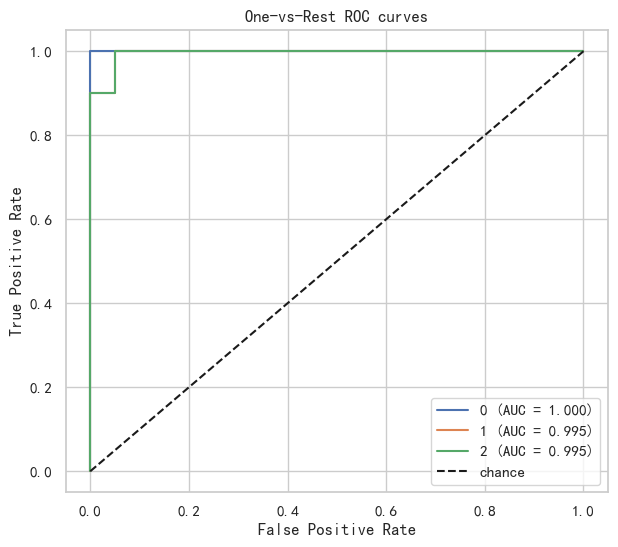

Macro AUC: 0.997, Micro AUC: 0.998


In [38]:
# 步骤5：计算分类指标并绘制 ROC 曲线
# - classification_report 展示精确率/召回率/F1，帮助比较类别性能
# - RocCurveDisplay.from_estimator 自动绘制多分类 ROC（一对多），AUC 衡量整体区分能力
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    roc_auc_score
)

# classification_report 会逐类输出 precision/recall/F1，观测是否存在难以识别的类别
print(classification_report(y_test, y_pred_logit, digits=3))
# confusion_matrix 统计每个真实类别被判到哪个类别，定位具体误判来源
print("\n混淆矩阵:\n", confusion_matrix(y_test, y_pred_logit))


# 替换原来的 RocCurveDisplay.from_estimator(...) 调用
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# 将多类标签二值化，classes 顺序可用模型的 classes_ 确保一致
classes = np.unique(y_test)  # 或 logit_clf.classes_
y_test_bin = label_binarize(y_test, classes=classes)

# 模型的预测概率 (n_samples, n_classes)
y_score = logit_clf.predict_proba(X_test_scaled)

n_classes = y_score.shape[1]
fig, ax = plt.subplots(figsize=(7, 6))

for i, class_label in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{class_label} (AUC = {roc_auc:.3f})")

# chance line
ax.plot([0, 1], [0, 1], "k--", label="chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("One-vs-Rest ROC curves")
ax.legend(loc="lower right")
plt.show()

# 计算 macro / micro AUC 的示例
macro_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")
micro_auc = roc_auc_score(y_test_bin, y_score, average="micro", multi_class="ovr")
print(f"Macro AUC: {macro_auc:.3f}, Micro AUC: {micro_auc:.3f}")

In [39]:
# 步骤6：提取逻辑回归系数并排序
# - 系数与特征顺序一一对应，可直接使用 X_train_scaled.columns 获取列名
# - 取绝对值是为了聚焦影响力度，而非方向
logit_feature_names = X_train_scaled.columns
logit_coef = logit_clf.coef_
logit_importance = np.mean(np.abs(logit_coef), axis=0)

importance_df = pd.DataFrame({
    "feature": logit_feature_names,
    "importance": logit_importance
}).sort_values("importance", ascending=False)
importance_df.head(10)

,feature,importance
3,petal width (cm),1.552183
2,petal length (cm),1.221445
5,petal_length_bin_短,0.630041
0,sepal length (cm),0.585538
1,sepal width (cm),0.562141
4,petal_length_bin_中,0.420227
6,petal_length_bin_长,0.381759


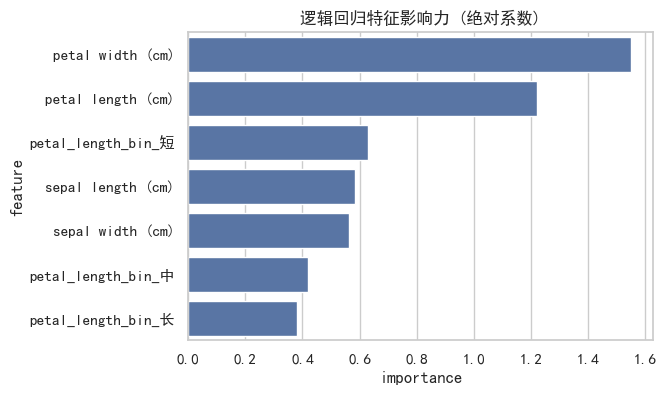

In [40]:
# 步骤6补充：可视化逻辑回归特征影响力
# - 纵轴为独热后的特征（含分箱后的类别），横轴为绝对系数大小
# - 柱越长，说明该特征对分类边界贡献越大，可在报告中重点解释
plt.figure(figsize=(6, 4))
sns.barplot(data=importance_df, x="importance", y="feature")
plt.title("逻辑回归特征影响力 (绝对系数)")
plt.show()

## 随机森林模型（额外示例）
> Notebook 要求包含随机森林示例，便于与逻辑回归对比。

In [41]:
# 步骤7：训练随机森林以便与逻辑回归对比
# - 随机森林属于树模型，对未缩放的特征也能工作，但沿用同一数据版本便于复现实验
# - n_estimators=300、max_depth=6 只是示例，可根据 HR 数据集调参
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    random_state=42,
    class_weight=None
)

# 在训练集上拟合随机森林模型
rf_clf.fit(X_train_scaled, y_train)

# 在测试集上做预测并查看分类报告
y_pred_rf = rf_clf.predict(X_test_scaled)
rf_acc = accuracy_score(y_test, y_pred_rf)
print(f"RandomForest Accuracy: {rf_acc:.3f}")
# classification_report 同样用于衡量每个类别的 precision/recall/F1，以判定相对表现
print(classification_report(y_test, y_pred_rf, digits=3))

RandomForest Accuracy: 0.933
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        10
           1      0.900     0.900     0.900        10
           2      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30




混淆矩阵:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


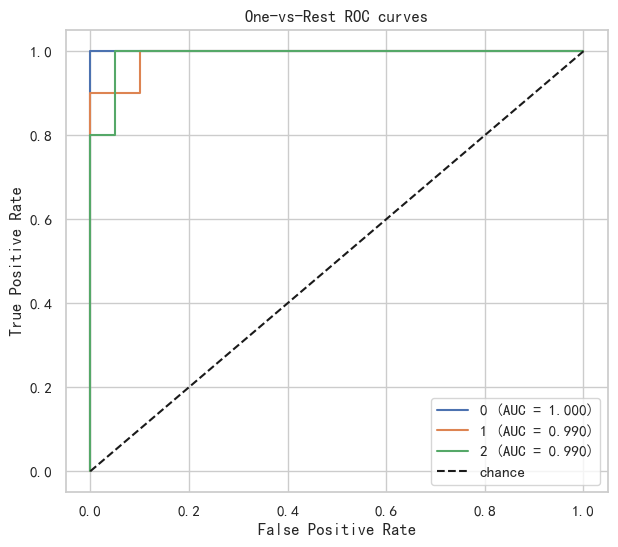

Macro AUC: 0.993, Micro AUC: 0.996


In [42]:
# 步骤7补充：查看随机森林的混淆矩阵与 ROC
# - 混淆矩阵便于定位某些类别被误判到何处，进而决定是否调整 class_weight
# - ROC 曲线可视化不同阈值下的真阳/假阳率，适合写入实验报告
# confusion_matrix 输出真实与预测类别的交叉频次，快速识别系统性错误
print("\n混淆矩阵:\n", confusion_matrix(y_test, y_pred_rf))

# 将多类标签二值化，classes 顺序可用模型的 classes_ 确保一致
classes = np.unique(y_test)  # 或 logit_clf.classes_
y_test_bin = label_binarize(y_test, classes=classes)

# 模型的预测概率 (n_samples, n_classes)
# 注意这里使用 rf_clf 而非 logit_clf
y_score = rf_clf.predict_proba(X_test_scaled)

n_classes = y_score.shape[1]
fig, ax = plt.subplots(figsize=(7, 6))

for i, class_label in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{class_label} (AUC = {roc_auc:.3f})")

# chance line
ax.plot([0, 1], [0, 1], "k--", label="chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("One-vs-Rest ROC curves")
ax.legend(loc="lower right")
plt.show()

# 计算 macro / micro AUC 的示例
macro_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")
micro_auc = roc_auc_score(y_test_bin, y_score, average="micro", multi_class="ovr")
print(f"Macro AUC: {macro_auc:.3f}, Micro AUC: {micro_auc:.3f}")

In [43]:
# 步骤8：提取随机森林的特征重要度
# - feature_importances_ 表示每个特征在分裂节点中的贡献权重，可与逻辑回归结果对照
rf_feature_names = X_train_scaled.columns
rf_importances = rf_clf.feature_importances_
rf_importance_df = pd.DataFrame({
    "feature": rf_feature_names,
    "importance": rf_importances
}).sort_values("importance", ascending=False)
rf_importance_df.head(10)

,feature,importance
2,petal length (cm),0.314240
3,petal width (cm),0.296231
5,petal_length_bin_短,0.155636
0,sepal length (cm),0.119176
6,petal_length_bin_长,0.057487
1,sepal width (cm),0.038369
4,petal_length_bin_中,0.018863


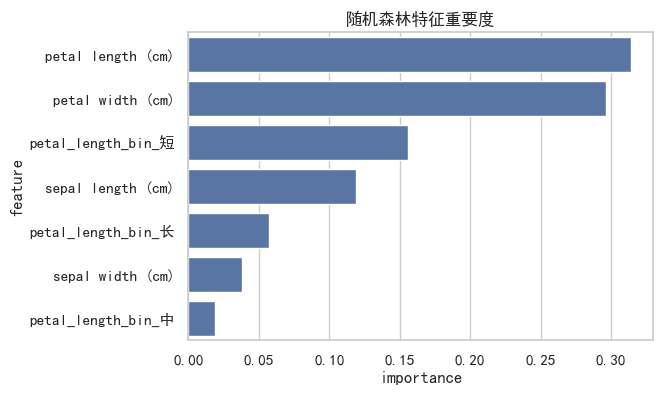

In [44]:
# 步骤8补充：可视化随机森林特征重要度
# - 与逻辑回归图一样展示前若干重要特征，帮助学生比较模型解释
# - 若类别型独热特征过多，可取 head() 结果后绘图以保持可读性
plt.figure(figsize=(6, 4))
sns.barplot(data=rf_importance_df, x="importance", y="feature")
plt.title("随机森林特征重要度")
plt.show()

## 保存模型供后续复用

In [45]:
# 步骤9：将训练好的物件持久化，便于在 HR 数据上复用
# - 分别保存 scaler、逻辑回归模型和随机森林模型，后续加载时依次还原相同流程
# - joblib.dump 可序列化任意 Python 对象，路径中若不存在会自动创建目录
import joblib

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

scaler_path = model_dir / "scaler.joblib"
logit_path = model_dir / "logit_model.joblib"
rf_path = model_dir / "rf_model.joblib"

joblib.dump(scaler, scaler_path)
joblib.dump(logit_clf, logit_path)
joblib.dump(rf_clf, rf_path)
print(f"已保存模型至 {model_dir.resolve()}")

已保存模型至 D:\OneDrive\工作科研\教学\商业数据挖掘\0-商业数据挖掘-授课\课件\实验1_企业员工流失预警\exp1_project\models


## 下一步建议
- 使用企业 HR 数据集重新执行同样的流程，检查是否存在类别不平衡并视情况应用 `class_weight` 或过采样。
- 增加更多分类算法（SVC、KNN、MLP 等）并写入实验报告比较结果。
- 将关键图表和指标复制到实验报告的相应章节（探索性分析、模型评估、特征影响描述）。